# Cruce SCADA × EQ con la herramienta del paquete

**Objetivo.** Repetir el cruce de energía contra baterías equivalentes (EQ) de
`eda_cruce_equ_energia.ipynb`, pero **usando solo la herramienta** que ahora vive en el paquete:
`energy.pipelines.flows.energy_cross` (la misma que corre `make cruce`). Este notebook no tiene
copias propias de la lógica: no calcula consumos por intervalo, no detecta contadores congelados
ni interpola medianoches. Todo eso lo hace la herramienta, y aquí solo se mira lo que entrega.

**Alcance.** Todas las áreas de baterías con energía, contra las EQ que calcula la base de
datos (`gold.v_resumen_equ_diario`, por medio de `BatterySeries`):

- **F&A** contra FORMACION + DECORADO: **diario** con los tres rectificadores del SCADA (desde
  julio de 2026) y **mensual** con el SCADA donde cubre el mes completo y, si no, con
  `Base_de_datos.xlsx`.
- **OREC** y **Ensamble**: solo **mensual**, con `Base_de_datos.xlsx`. La sección 8 muestra por
  qué el medidor EMCALI no sirve para darles energía diaria.

SHIPPING no tiene energía. RC tiene energía y gas, pero no tiene EQ, así que queda fuera del
cruce. Las secciones 1 a 4 miran F&A día a día y las 5 a 8 agregan los demás procesos.

**Reglas que aplica la herramienta** (`energy.domain.energy_cross`):

- **Día local.** El día D va de las 00:00 a las 24:00 de Bogotá, como `fecha_efectiva`. Las
  lecturas llegan al minuto 24:49 de cada hora, así que el contador se **interpola linealmente
  en cada medianoche**: kWh del día D = contador(D+1 00:00) − contador(D 00:00).
- **Contador congelado.** Un medidor quieto **3 h o más** mientras un hermano se mueve, **y** cuyo
  intervalo siguiente salta por encima de su límite físico (2 × el percentil 99 de sus horas de
  operación). La racha y el salto quedan **faltantes, nunca 0**. Una racha sin salto es una
  **parada real** y sus ceros son ceros reales.
- **Periodo.** Los kWh de un mes o de un rango son la diferencia del contador entre su primera y
  su última medianoche: un contador acumulado no pierde energía al congelarse, solo se pierde
  *cuándo* se usó.
- **Caídas y reinicios.** Si un contador pierde **más de la mitad** de su valor, es un
  reinicio (*reset*) y ninguna diferencia lo atraviesa. Si la caída es menor, es una lectura
  mala (*dip*): su día queda faltante, pero el mes conserva la diferencia del contador.
- **Fuentes por prioridad.** Cada fila toma la primera fuente con kWh completos (SCADA, luego el
  libro) y lo dice en `energy_source`.
- **Razón.** kWh por EQ = **Σ kWh / Σ EQ** del mismo periodo, nunca el promedio de razones.

**Convención.** El código está en inglés (regla del repositorio); el texto, en español.

**Contenido.**

1. Cruce diario y cobertura.
2. Cruce mensual.
3. El contador congelado: cómo lo trata la herramienta.
4. Relación entre kWh y EQ: correlación, rezago y razón móvil de 7 días.
5. kWh por EQ mensual de todos los procesos de baterías, con su fuente (FY26).
6. Cobertura por fuente.
7. Chequeo de julio de 2026: SCADA contra `Base_de_datos.xlsx`.
8. ¿Qué mide EMCALI? Investigación y veredicto.
9. Componentes y mezcla de F&A, día a día y por semana.
10. OREC y Ensamble: razón mensual y mezcla.
11. Resultados principales.

## 0. Conexión a la base de datos (solo lectura)

La base de datos **no publica ningún puerto** (solo Caddy lo hace). Para leer desde el equipo se
levanta un **relé temporal** (socat) en la red interna de Docker, escuchando solo en
`127.0.0.1:5433`. La conexión se abre con `default_transaction_read_only=on`: el notebook no
puede escribir en la base aunque quisiera.

**Antes de ejecutar** (con `make up` ya arriba):

```bash
docker run --rm -d --name db-tunnel --network clarios-energy_backend \
  -p 127.0.0.1:5433:5432 alpine/socat \
  tcp-listen:5432,fork,reuseaddr tcp-connect:db:5432
```

**Al terminar:**

```bash
docker rm -f db-tunnel
```

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import dotenv_values
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sqlalchemy.exc import OperationalError

from energy.domain.energy_cross import (
    AreaCross,
    energy_intensity,
    fiscal_label,
    fiscal_month,
    fiscal_year,
    meter_months,
)
from energy.domain.equs_gold import DateRange
from energy.pipelines.flows.energy_cross import (
    ENERGY_BOOK,
    FA_AREA,
    FA_WORKBOOK,
    RC_AREA,
    RC_BUILDING_METER,
    RC_MAIN_METER,
    RC_PLANT_METERS,
    SCADA_ZONE,
    build_cross,
    energy_sources,
    rc_sources,
)

REPO_ROOT = Path.cwd().parent
DATA_DIR = REPO_ROOT / "data"
RELAY_HOST, RELAY_PORT = "127.0.0.1", 5433

# The whole local days of the SCADA export: its first reading is 2026-07-01 19:24 and its last
# 2026-10-01 18:24, so July 1 and October 1 are not whole days.
CROSS_RANGE = DateRange(date(2026, 7, 2), date(2026, 9, 30))
ROLLING_DAYS = 7
LAGS = range(-2, 3)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)

In [2]:
env = dotenv_values(REPO_ROOT / ".env")
engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=env["POSTGRES_USER"],
        password=env["POSTGRES_PASSWORD"],
        host=RELAY_HOST,
        port=RELAY_PORT,
        database=env["POSTGRES_DB"],
    ),
    connect_args={"options": "-c default_transaction_read_only=on"},
)
try:
    with engine.connect() as connection:
        head = connection.execute(text("SELECT version_num FROM alembic_version")).scalar_one()
        read_only = connection.execute(text("SHOW default_transaction_read_only")).scalar_one()
except OperationalError as error:
    raise RuntimeError(
        f"No database on {RELAY_HOST}:{RELAY_PORT}: start the relay (see the cell above)"
    ) from error
print(f"Connected through the relay: Alembic head {head}, read-only = {read_only}")

Connected through the relay: Alembic head 0006, read-only = on


## 1. Cruce diario y cobertura

Una sola llamada a la herramienta da, para cada día del rango, los kWh de los tres
rectificadores, la cobertura (qué parte del día cae en intervalos utilizables), las EQ de
FORMACION y DECORADO del mismo día y su razón. Un día sin kWh completos queda vacío, nunca en 0.

In [3]:
cross = build_cross(data_dir=DATA_DIR, engine=engine)
daily_series = cross.cross(CROSS_RANGE, areas=[FA_AREA])
monthly_series = cross.cross(CROSS_RANGE, frequency="month", areas=[FA_AREA])
(fa_daily,) = daily_series.areas
(fa_monthly,) = monthly_series.areas


def rows_frame(area: AreaCross) -> pd.DataFrame:
    """One row per day or month of a cross, as floats; a missing kWh is NaN, never 0."""

    def number(value: object) -> float:
        return float("nan") if value is None else float(value)  # type: ignore[arg-type]

    records = [
        {
            "start": pd.Timestamp(row.start),
            "end": pd.Timestamp(row.end),
            "days": row.days,
            "measured_days": row.measured_days,
            "coverage": number(row.coverage),
            "kwh": number(row.kwh),
            "eq": number(row.eq),
            **{f"eq_{name.lower()}": number(value) for name, value in row.eq_by_process.items()},
            "kwh_per_eq": number(row.kwh_per_eq),
            "energy_source": row.energy_source,
        }
        for row in area.rows
    ]
    return pd.DataFrame(records).set_index("start")


daily = rows_frame(fa_daily)
fiscal = fiscal_label(fiscal_year(CROSS_RANGE.start))
first_month, last_month = fiscal_month(CROSS_RANGE.start), fiscal_month(CROSS_RANGE.end)
print(f"Area {fa_daily.area}: {fa_daily.energy.source}, meters {', '.join(fa_daily.energy.meters)}")
print(f"EQ of {' + '.join(fa_daily.procesos)}; range {CROSS_RANGE.start} to {CROSS_RANGE.end} "
      f"({fiscal}, fiscal months {first_month} to {last_month})")  # fmt: skip
print(f"Days: {fa_daily.total.days}, with a measured kWh: {fa_daily.total.measured_days}; "
      f"coverage of the range {float(fa_daily.total.coverage):.1%}")  # fmt: skip
print("Daily EQ reconciled with gold.v_resumen_equ:",
      ", ".join(f"{m:%Y-%m}" for m in fa_daily.reconciled_months),
      f"({fa_daily.eq_mismatches} differences)")  # fmt: skip
display(daily.head(10))

Area F&A: SCADA-Base de datos F&A.xlsx, meters RECTIFICADOR 1, RECTIFICADOR 2, RECTIFICADOR 3
EQ of FORMACION + DECORADO; range 2026-07-02 to 2026-09-30 (FY26, fiscal months 10 to 12)
Days: 91, with a measured kWh: 86; coverage of the range 98.5%
Daily EQ reconciled with gold.v_resumen_equ: 2026-08, 2026-09 (0 differences)


,end,days,measured_days,coverage,kwh,eq,eq_formacion,eq_decorado,kwh_per_eq,energy_source
start,,,,,,,,,,
2026-07-02,2026-07-02,1,1,1.00,"22,637.91",948.79,555.37,393.42,23.86,SCADA-Base de datos F&A.xlsx
2026-07-03,2026-07-03,1,1,1.00,"32,997.96","1,381.37",699.76,681.61,23.89,SCADA-Base de datos F&A.xlsx
2026-07-04,2026-07-04,1,1,1.00,"26,921.41","1,458.64",694.30,764.34,18.46,SCADA-Base de datos F&A.xlsx
2026-07-05,2026-07-05,1,1,1.00,"3,001.64",0.00,0.00,0.00,NaN,SCADA-Base de datos F&A.xlsx
2026-07-06,2026-07-06,1,1,1.00,"48,035.61","2,667.83","1,329.77","1,338.06",18.01,SCADA-Base de datos F&A.xlsx
2026-07-07,2026-07-07,1,1,1.00,"44,218.42","2,037.27","1,189.42",847.84,21.70,SCADA-Base de datos F&A.xlsx
2026-07-08,2026-07-08,1,1,1.00,"52,615.51","2,358.91","1,392.51",966.40,22.31,SCADA-Base de datos F&A.xlsx
2026-07-09,2026-07-09,1,1,1.00,"57,229.39","2,449.94","1,563.35",886.59,23.36,SCADA-Base de datos F&A.xlsx
2026-07-10,2026-07-10,1,1,1.00,"50,116.96","2,106.42","1,411.43",694.99,23.79,SCADA-Base de datos F&A.xlsx


In [4]:
missing = daily[daily["kwh"].isna()]
display(missing[["coverage", "eq", "eq_formacion", "eq_decorado"]].rename_axis("day without kWh"))

coverage_by_month = daily.groupby(daily.index.to_period("M")).agg(
    days=("days", "sum"),
    measured_days=("measured_days", "sum"),
    coverage=("coverage", "mean"),
    eq_of_missing_days=("eq", lambda eq: eq[daily.loc[eq.index, "kwh"].isna()].sum()),
)
display(coverage_by_month)

,coverage,eq,eq_formacion,eq_decorado
day without kWh,,,,
2026-07-18,0.95,"1,396.01",800.77,595.24
2026-07-19,0.67,0.00,0.00,0.00
2026-07-20,0.67,0.00,0.00,0.00
2026-07-21,0.67,"2,311.22","1,394.63",916.59
2026-07-22,0.70,"2,761.63","1,414.98","1,346.65"


,days,measured_days,coverage,eq_of_missing_days
start,,,,
2026-07,30,25,0.96,"6,468.85"
2026-08,31,31,1.00,0.00
2026-09,30,30,1.00,0.00


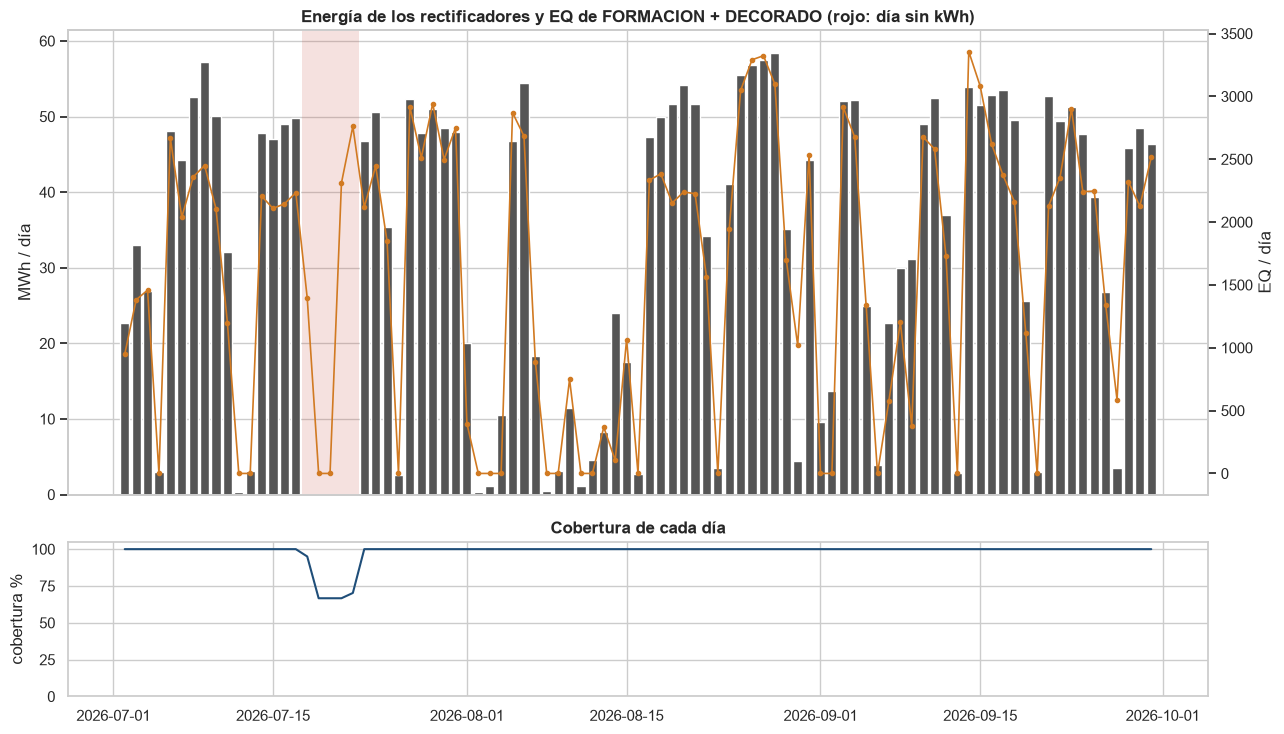

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, height_ratios=[3, 1])
axes[0].bar(daily.index, daily["kwh"] / 1000, color="#555555", label="rectificadores (MWh)")
for day in missing.index:
    axes[0].axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12),
                    color="#c0392b", alpha=0.15, lw=0)  # fmt: skip
axes[0].set_ylabel("MWh / día")
twin = axes[0].twinx()
twin.plot(daily.index, daily["eq"], color="#d17a22", marker="o", ms=3, lw=1.2, label="EQ F+D")
twin.set_ylabel("EQ / día")
twin.grid(False)
axes[0].set_title("Energía de los rectificadores y EQ de FORMACION + DECORADO (rojo: día sin kWh)")
axes[1].plot(daily.index, daily["coverage"] * 100, color="#1f4e79", lw=1.5)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("cobertura %")
axes[1].set_title("Cobertura de cada día")
plt.tight_layout()
plt.show()

**Cómo leerlo.** De los 91 días completos del export, **86 tienen kWh**. Los 5 que faltan
(18 a 22 de julio) son los del contador congelado del rectificador 2 (sección 3). Ahí la
cobertura baja a 67-95 %: los otros dos rectificadores siguen medidos, pero un día de F&A solo
tiene kWh si los tres los tienen. Tres de esos días **sí tienen EQ** (18, 21 y 22 de julio): la
producción siguió y solo falta saber cuánta energía usó cada día. El 19 (domingo) y el 20 (festivo
del 20 de julio) no tienen EQ. Esas EQ quedan fuera de las razones diarias, pero no de la del mes
ni la del rango, que también llevan la energía de esos días.

## 2. Cruce mensual

El mes toma la diferencia del contador entre su primera y su última medianoche, así que julio
conserva la energía de los días congelados aunque esos días no tengan kWh propios. Julio empieza
el día 2, porque el 1 no está completo en el export. La herramienta recorta el mes al rango y le
asigna las EQ de esos mismos días.

In [6]:
monthly = rows_frame(fa_monthly)
monthly["kwh_per_eq_formacion"] = [
    float(ratio) if (ratio := energy_intensity(row.kwh, row.eq_by_process["FORMACION"])) else np.nan
    for row in fa_monthly.rows
]
monthly.index = monthly.index.strftime("%Y-%m")
display(monthly[["end", "days", "measured_days", "coverage", "kwh", "eq", "kwh_per_eq",
                 "kwh_per_eq_formacion"]])  # fmt: skip

total = fa_monthly.total
print(f"Range: {float(total.kwh):,.2f} kWh / {float(total.eq):,.2f} EQ = "
      f"{float(total.kwh_per_eq):.2f} kWh per EQ (FORMACION + DECORADO)")  # fmt: skip
formacion_eq = total.eq_by_process["FORMACION"]
print(f"Against FORMACION alone: {float(energy_intensity(total.kwh, formacion_eq)):.2f} kWh per EQ")

,end,days,measured_days,coverage,kwh,eq,kwh_per_eq,kwh_per_eq_formacion
start,,,,,,,,
2026-07,2026-07-31,30,25,0.96,"1,084,695.90","51,801.20",20.94,37.84
2026-08,2026-08-31,31,31,1.00,"870,272.69","41,993.63",20.72,37.95
2026-09,2026-09-30,30,30,1.00,"1,083,093.03","51,555.86",21.01,38.76


Range: 3,038,061.61 kWh / 145,350.69 EQ = 20.90 kWh per EQ (FORMACION + DECORADO)
Against FORMACION alone: 38.19 kWh per EQ


**Cómo leerlo.** La razón del rango (Σ kWh / Σ EQ) es **20,90 kWh por EQ**, la misma cifra del
notebook anterior. Allí se repartía el salto del contador congelado sobre sus horas; aquí esos
días quedan sin kWh, pero el total del rango no cambia porque es la diferencia del contador. Los
tres meses quedan entre 20,7 y 21,0: la razón es estable mes a mes. Contra FORMACION sola la
razón casi se duplica: DECORADO aporta cerca de la mitad de las EQ, y los rectificadores miden la
energía de formación (DECORADO no tiene medidor propio).

## 3. El contador congelado

La herramienta clasifica cada intervalo entre lecturas de cada rectificador como `ok`, `frozen`
(racha quieta), `jump` (el salto que la libera), `reset` (contador que baja) o `unread` (lectura
vacía). Aquí se mira esa clasificación tal como la entrega, sin recalcularla.

In [7]:
scada = energy_sources(DATA_DIR)[0]  # the SCADA counters come first
counters = scada.counters(FA_AREA)  # type: ignore[attr-defined]

limits = pd.Series({meter: float(limit) for meter, limit in counters.limits.items()},
                   name="physical limit (kWh per hour)")  # fmt: skip
display(limits.to_frame())

frozen_runs = pd.DataFrame(
    [
        {
            "meter": run.meter,
            "still from (local)": run.start.astimezone(SCADA_ZONE).replace(tzinfo=None),
            "jump from (local)": run.end.astimezone(SCADA_ZONE).replace(tzinfo=None),
            "hours still": float(run.hours),
            "jump kWh": float(run.jump_kwh),
            "jump vs limit": float(run.jump_kwh) / float(run.limit_kwh_per_hour),
        }
        for run in counters.frozen
    ]
)
display(frozen_runs)

,physical limit (kWh per hour)
RECTIFICADOR 1,"2,507.57"
RECTIFICADOR 2,"2,465.79"
RECTIFICADOR 3,"1,359.87"


,meter,still from (local),jump from (local),hours still,jump kWh,jump vs limit
0,RECTIFICADOR 2,2026-07-18 20:24:49.746,2026-07-22 20:24:49.746,96.00,"33,955.84",13.77


In [8]:
def interval_frame(meter: str) -> pd.DataFrame:
    """Every interval of one meter as the tool classified it, by local start."""
    return pd.DataFrame(
        [
            {
                "start": item.start.astimezone(SCADA_ZONE).replace(tzinfo=None),
                "kwh": float("nan") if item.kwh is None else float(item.kwh),
                "difference": float("nan") if item.difference is None else float(item.difference),
                "state": item.state,
            }
            for item in counters.intervals[meter]
        ]
    ).set_index("start")


intervals = {meter: interval_frame(meter) for meter in counters.meters}
states = pd.DataFrame({meter: frame["state"].value_counts() for meter, frame in intervals.items()})
display(states.fillna(0).astype(int).rename_axis("interval state"))

real_zero_hours = pd.Series(
    {
        meter: int(((frame["state"] == "ok") & (frame["kwh"] == 0)).sum())
        for meter, frame in intervals.items()
    },
    name="hours at a real 0",
)
display(real_zero_hours.to_frame())

,RECTIFICADOR 1,RECTIFICADOR 2,RECTIFICADOR 3
interval state,,,
frozen,0,96,0
jump,0,1,0
ok,2207,2110,2207


,hours at a real 0
RECTIFICADOR 1,540
RECTIFICADOR 2,500
RECTIFICADOR 3,43


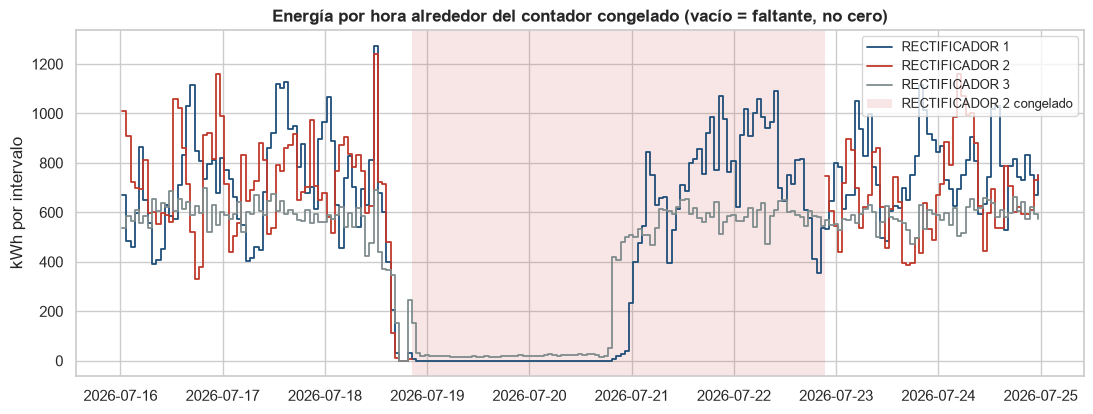

meter,RECTIFICADOR 1,RECTIFICADOR 2,RECTIFICADOR 3
day,,,
2026-07-17,ok,ok,ok
2026-07-18,ok,frozen,ok
2026-07-19,ok,frozen,ok
2026-07-20,ok,frozen,ok
2026-07-21,ok,frozen,ok
2026-07-22,ok,frozen,ok
2026-07-23,ok,ok,ok


In [9]:
window = slice(pd.Timestamp("2026-07-16"), pd.Timestamp("2026-07-25"))
fig, ax = plt.subplots(figsize=(13, 4.5))
colors = {"RECTIFICADOR 1": "#1f4e79", "RECTIFICADOR 2": "#c0392b", "RECTIFICADOR 3": "#7f8c8d"}
for meter, frame in intervals.items():
    part = frame.loc[window]
    ax.step(part.index, part["kwh"], where="post", color=colors[meter], lw=1.3, label=meter)
for run in counters.frozen:
    ax.axvspan(run.start.astimezone(SCADA_ZONE).replace(tzinfo=None),
               run.jump_end.astimezone(SCADA_ZONE).replace(tzinfo=None),
               color="#c0392b", alpha=0.12, lw=0, label=f"{run.meter} congelado")  # fmt: skip
ax.set_ylabel("kWh por intervalo")
ax.set_title("Energía por hora alrededor del contador congelado (vacío = faltante, no cero)")
ax.legend(loc="upper right", fontsize=9)
plt.show()

meter_days = pd.DataFrame(
    [
        {
            "day": row.day,
            "meter": row.meter,
            "kwh": row.kwh,
            "state": row.state,
            "coverage": float(row.coverage),
        }
        for row in fa_daily.energy.meter_days
        if date(2026, 7, 17) <= row.day <= date(2026, 7, 23)
    ]
)
display(meter_days.pivot(index="day", columns="meter", values="state"))

In [10]:
measured_kwh = daily["kwh"].sum()  # the days with a kWh of their own
range_kwh = float(fa_daily.total.kwh)
print(f"kWh of the range (counter difference): {range_kwh:,.2f}")
print(f"kWh of the 86 measured days:          {measured_kwh:,.2f}")
print(f"Energy of the 5 frozen days, kept only in the range and the month: "
      f"{range_kwh - measured_kwh:,.2f} kWh")  # fmt: skip

kWh of the range (counter difference): 3,038,061.61
kWh of the 86 measured days:          2,903,316.20
Energy of the 5 frozen days, kept only in the range and the month: 134,745.41 kWh


**Cómo leerlo.**

- **Solo hay un contador congelado** en todo el export: el rectificador 2, quieto 96 horas
  (18 al 22 de julio) mientras el 3 seguía trabajando, y luego un salto de 33.956 kWh en una sola
  hora, unas 14 veces su límite físico. La herramienta deja faltantes esas 96 horas y el salto.
- **Los demás ceros son paradas reales.** Los rectificadores 1 y 2 suman 540 y 500 horas en un 0
  real: se detienen juntos, casi siempre en fin de semana, mientras el 3 sigue, y al volver arrancan
  con pocos kWh, nada parecido a un salto. Exigir solo "quieto 3 h mientras un hermano se mueve"
  convertiría esas paradas en faltantes. Por eso la regla también pide el salto.
- **La energía no se pierde.** Los 5 días congelados no tienen kWh propios, pero el mes y el rango
  sí la incluyen, porque son diferencias del contador acumulado.

## 4. Relación entre kWh y EQ

Con los días medidos se mira si la energía acompaña a la producción del mismo día, si hay
rezago (la EQ de formación se registra al terminar la batería, y `fecha_efectiva` es contable)
y qué tan estable es la razón en ventanas de 7 días. La ventana móvil es **Σ kWh / Σ EQ** de 7
días seguidos y exige los 7 días medidos: una ventana que toca un día sin kWh queda vacía.

In [11]:
lag_rows = []
for lag in LAGS:
    shifted = daily["eq"].shift(-lag)
    valid = daily["kwh"].notna() & shifted.notna()
    lag_rows.append(
        {
            "lag_days (EQ of t + k)": lag,
            "pairs": int(valid.sum()),
            "pearson": daily["kwh"][valid].corr(shifted[valid]),
            "spearman": daily["kwh"][valid].corr(shifted[valid], method="spearman"),
        }
    )
lags = pd.DataFrame(lag_rows).set_index("lag_days (EQ of t + k)")
display(lags)
best_lag = int(lags["pearson"].idxmax())
print(f"Highest Pearson correlation at k = {best_lag:+d} day(s)")

,pairs,pearson,spearman
lag_days (EQ of t + k),,,
-2,84,0.03,0.03
-1,85,0.42,0.43
0,86,0.95,0.91
1,85,0.40,0.39
2,84,0.01,-0.01


Highest Pearson correlation at k = +0 day(s)


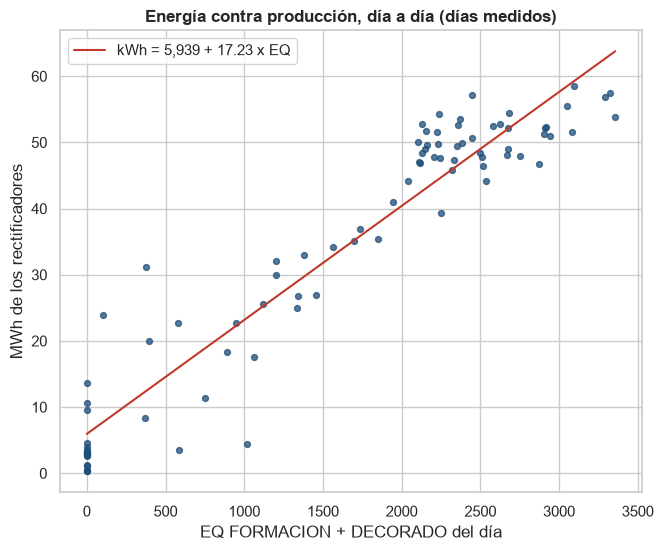

Measured days: 86, of which with EQ > 0: 68
Fit: 5,939 kWh a day at zero EQ, plus 17.23 kWh per EQ


In [12]:
measured = daily.dropna(subset=["kwh"])
slope, intercept = np.polyfit(measured["eq"], measured["kwh"], 1)
producing = measured[measured["eq"] > 0]

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(measured["eq"], measured["kwh"] / 1000, s=18, color="#1f4e79", alpha=0.75)
line = np.linspace(0, measured["eq"].max(), 50)
ax.plot(line, (intercept + slope * line) / 1000, color="#c0392b", lw=1.5,
        label=f"kWh = {intercept:,.0f} + {slope:,.2f} x EQ")  # fmt: skip
ax.set_xlabel("EQ FORMACION + DECORADO del día")
ax.set_ylabel("MWh de los rectificadores")
ax.set_title("Energía contra producción, día a día (días medidos)")
ax.legend()
plt.show()

print(f"Measured days: {len(measured)}, of which with EQ > 0: {len(producing)}")
print(f"Fit: {intercept:,.0f} kWh a day at zero EQ, plus {slope:.2f} kWh per EQ")

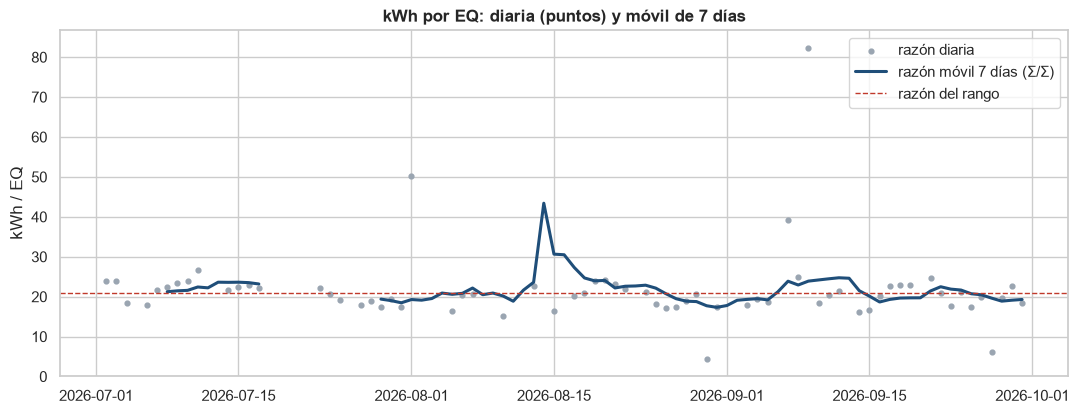

,"kWh per EQ, F&A"
range ratio (Σ/Σ),20.90
daily median,20.62
daily p10,17.09
daily p90,24.38
7-day min,17.32
7-day median,21.22
7-day max,43.40
7-day windows,74.00


Highest 7-day ratio: 2026-08-08 to 2026-08-14, 1,221 EQ against a median week of 11,484 EQ


In [13]:
rolling_kwh = daily["kwh"].rolling(ROLLING_DAYS, min_periods=ROLLING_DAYS).sum()
rolling_eq = daily["eq"].rolling(ROLLING_DAYS, min_periods=ROLLING_DAYS).sum()
daily["rolling_kwh_per_eq"] = rolling_kwh / rolling_eq.where(rolling_eq > 0)
daily_ratio = daily["kwh_per_eq"].dropna()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.scatter(daily_ratio.index, daily_ratio, s=12, color="#9aa5b1", label="razón diaria")
ax.plot(daily.index, daily["rolling_kwh_per_eq"], color="#1f4e79", lw=2.2,
        label=f"razón móvil {ROLLING_DAYS} días (Σ/Σ)")  # fmt: skip
ax.axhline(float(fa_daily.total.kwh_per_eq), color="#c0392b", ls="--", lw=1,
           label="razón del rango")  # fmt: skip
ax.set_ylim(0, daily["rolling_kwh_per_eq"].max() * 2)
ax.set_ylabel("kWh / EQ")
ax.set_title("kWh por EQ: diaria (puntos) y móvil de 7 días")
ax.legend(loc="upper right")
plt.show()

summary = pd.Series(
    {
        "range ratio (Σ/Σ)": float(fa_daily.total.kwh_per_eq),
        "daily median": daily_ratio.median(),
        "daily p10": daily_ratio.quantile(0.10),
        "daily p90": daily_ratio.quantile(0.90),
        "7-day min": daily["rolling_kwh_per_eq"].min(),
        "7-day median": daily["rolling_kwh_per_eq"].median(),
        "7-day max": daily["rolling_kwh_per_eq"].max(),
        "7-day windows": int(daily["rolling_kwh_per_eq"].notna().sum()),
    },
    name="kWh per EQ, F&A",
)
display(summary.to_frame())

peak_end = daily["rolling_kwh_per_eq"].idxmax()
peak = daily.loc[peak_end - pd.Timedelta(days=ROLLING_DAYS - 1) : peak_end]
weekly_eq = rolling_eq.median()
print(f"Highest 7-day ratio: {peak.index[0]:%Y-%m-%d} to {peak_end:%Y-%m-%d}, "
      f"{peak['eq'].sum():,.0f} EQ against a median week of {weekly_eq:,.0f} EQ")  # fmt: skip

**Cómo leerlo.**

- **Mismo día, sin rezago.** La correlación más alta está en k = 0: la energía y la EQ se mueven
  el mismo día contable, así que el cruce diario no necesita desplazar una serie respecto a la otra.
- **Hay una carga base.** La recta de ajuste no pasa por el origen: los rectificadores consumen
  algo aunque ese día no haya EQ (por ejemplo, baterías que se terminan de formar al día siguiente,
  o la carga en espera). Por eso la razón diaria se dispara los días de poca producción, y la
  razón de días sueltos sirve poco como indicador.
- **La ventana de 7 días es la medida estable.** Absorbe los fines de semana: su mediana (21,2)
  queda cerca de la razón del rango (20,9). Su máximo (43,4) es una semana de muy poca producción,
  donde la carga base pesa sobre pocas EQ; la celda de arriba muestra cuál. Las ventanas que tocan
  los días congelados quedan vacías en vez de mostrar un valor falso.

## 5. kWh por EQ de todos los procesos de baterías (FY26, mensual)

Ahora el cruce mensual incluye las tres áreas de baterías que tienen energía: **F&A**
(FORMACION + DECORADO), **OREC** y **Ensamble** (ENSAMBLE). SHIPPING no tiene medidor ni fila de
energía, así que no entra. Cada área tiene sus fuentes **en orden de prioridad**:

1. **SCADA** (contadores, por día): solo F&A, desde el 1 de julio de 2026 a las 19:24.
2. **`Base_de_datos.xlsx`** (por mes): la fila total de cada área y su columna `KWH`, nunca la
   columna `KWH por proceso`, que es un reparto por porcentajes fijos.

Cada mes toma la primera fuente que tiene sus kWh **completos**, y cada fila dice cuál usó en
`energy_source`. Un mes sin energía en ninguna fuente queda vacío y sus EQ se informan aparte
(`eq_without_energy`), fuera de la razón: la razón del año es Σ kWh / Σ EQ **de los mismos
meses**.

In [14]:
FY26 = DateRange(date(2025, 10, 1), date(2026, 9, 30))
fy_series = cross.cross(FY26, frequency="month")
fy_rows = pd.concat([rows_frame(area).assign(area=area.area) for area in fy_series.areas])
fy_rows.index = fy_rows.index.strftime("%Y-%m")
fy_rows.index.name = "month"
area_order = [area.area for area in fy_series.areas]

ratios = fy_rows.pivot(columns="area", values="kwh_per_eq")[area_order]
sources = fy_rows.pivot(columns="area", values="energy_source")[area_order].fillna("-")
display(ratios.join(sources, rsuffix=" source"))

area,F&A,OREC,Ensamble,F&A source,OREC source,Ensamble source
month,,,,,,
2025-10,20.69,6.11,2.35,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2025-11,19.63,7.61,3.36,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2025-12,20.88,7.03,2.87,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-01,20.28,6.75,2.94,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-02,20.62,6.20,2.81,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-03,20.72,7.38,5.37,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-04,22.38,6.02,3.81,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-05,22.62,6.90,3.10,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx
2026-06,19.17,6.71,2.42,Base_de_datos.xlsx,Base_de_datos.xlsx,Base_de_datos.xlsx


In [15]:
fy_totals = pd.DataFrame(
    [
        {
            "area": area.area,
            "processes": " + ".join(area.procesos),
            "kWh": float(area.total.kwh),
            "EQ (same months)": float(area.total.eq),
            "kWh per EQ": float(area.total.kwh_per_eq),
            "months with energy": sum(row.kwh is not None for row in area.rows),
            "EQ without energy": float(area.eq_without_energy),
            "energy source": area.total.energy_source,
        }
        for area in fy_series.areas
    ]
).set_index("area")
display(fy_totals)

,processes,kWh,EQ (same months),kWh per EQ,months with energy,EQ without energy,energy source
area,,,,,,,
F&A,FORMACION + DECORADO,"11,433,291.72","548,717.15",20.84,12,0.00,Base_de_datos.xlsx + SCADA-Base de datos F&A.xlsx
OREC,OREC,"3,888,712.90","582,074.99",6.68,9,"208,240.08",Base_de_datos.xlsx
Ensamble,ENSAMBLE,"2,265,491.00","737,795.83",3.07,10,"137,258.79",Base_de_datos.xlsx


### Dos cifras de F&A que no hay que confundir

| Cifra | Periodo | Fuente de la energía |
|---|---|---|
| **20,83** kWh por EQ | oct-2025 a **jul-2026** (10 meses) | solo `Base_de_datos.xlsx` |
| **20,84** kWh por EQ | **FY26 completo**, oct-2025 a sep-2026 (12 meses) | `Base_de_datos.xlsx` de octubre a julio + **SCADA** en agosto y septiembre |

La primera es la del notebook `eda_cruce_equ_energia.ipynb`, que solo tenía el libro. La segunda
es la del año fiscal completo, con la prioridad SCADA → libro. Julio queda con el libro en las
dos porque el SCADA no tiene el 1 de julio completo. Las dos están fijadas en
`tests/integration/test_energy_cross_build.py`.

In [16]:
book_only = cross.cross(
    DateRange(date(2025, 10, 1), date(2026, 7, 31)), frequency="month", areas=[FA_AREA]
).areas[0]
(fa_fy26,) = (area for area in fy_series.areas if area.area == FA_AREA)
fa_figures = pd.DataFrame(
    {
        "F&A, oct-2025 to jul-2026 (Base_de_datos only)": {
            "kWh per EQ": float(book_only.total.kwh_per_eq),
            "kWh": float(book_only.total.kwh),
            "EQ": float(book_only.total.eq),
            "energy source": book_only.total.energy_source,
        },
        "F&A, FY26 (Base_de_datos + SCADA Aug-Sep)": {
            "kWh per EQ": float(fa_fy26.total.kwh_per_eq),
            "kWh": float(fa_fy26.total.kwh),
            "EQ": float(fa_fy26.total.eq),
            "energy source": fa_fy26.total.energy_source,
        },
    }
)
display(fa_figures)

,"F&A, oct-2025 to jul-2026 (Base_de_datos only)","F&A, FY26 (Base_de_datos + SCADA Aug-Sep)"
kWh per EQ,20.83,20.84
kWh,"9,479,926.00","11,433,291.72"
EQ,"455,167.66","548,717.15"
energy source,Base_de_datos.xlsx,Base_de_datos.xlsx + SCADA-Base de datos F&A.xlsx


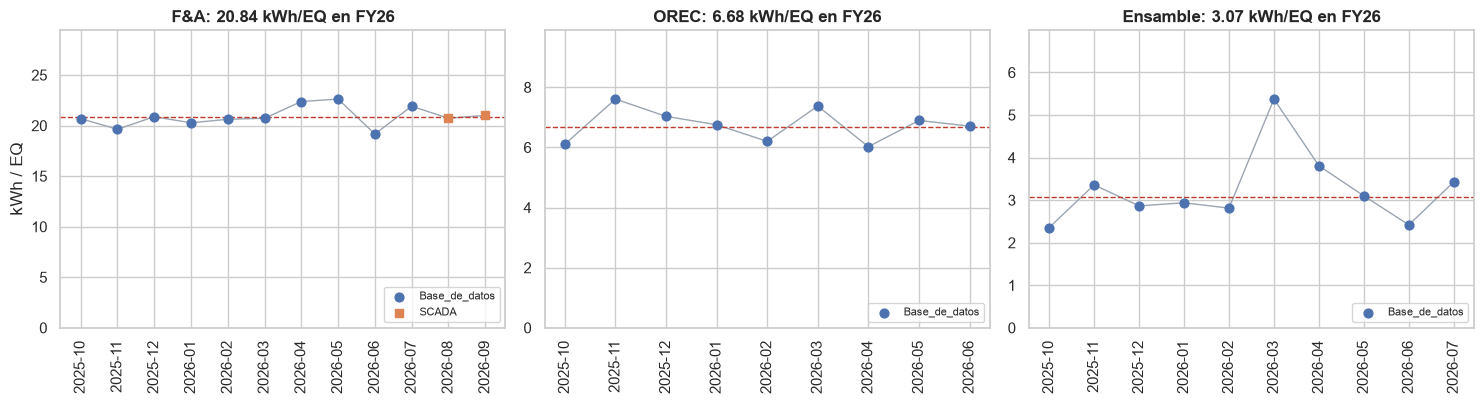

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
markers = {ENERGY_BOOK: "o", FA_WORKBOOK: "s"}
for ax, area in zip(axes, area_order, strict=True):
    part = fy_rows[fy_rows["area"] == area]
    ax.plot(part.index, part["kwh_per_eq"], color="#9aa5b1", lw=1)
    for source, marker in markers.items():
        points = part[part["energy_source"] == source]
        if points.empty:
            continue
        ax.scatter(points.index, points["kwh_per_eq"], marker=marker, s=40, zorder=3,
                   label="SCADA" if source == FA_WORKBOOK else "Base_de_datos")  # fmt: skip
    ax.axhline(fy_totals.loc[area, "kWh per EQ"], color="#c0392b", ls="--", lw=1)
    ax.set_title(f"{area}: {fy_totals.loc[area, 'kWh per EQ']:.2f} kWh/EQ en FY26")
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylim(0, part["kwh_per_eq"].max() * 1.3)
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("kWh / EQ")
plt.tight_layout()
plt.show()

**Cómo leerlo.** F&A gasta unas **20,8 kWh por EQ**, OREC unas **6,7** y Ensamble unas **3,1**.
Mes a mes, F&A se mueve entre 19,2 y 22,6. Ensamble salta a 5,4 en marzo de 2026, un mes de poca
producción (unas 37.000 EQ, cerca de la mitad de un mes normal) en el que la energía baja mucho
menos. OREC no tiene energía de julio a septiembre de 2026
(el libro llega hasta junio) y Ensamble no la tiene de agosto y septiembre: sus EQ de esos meses
quedan fuera de la razón y se informan en `EQ without energy`.

## 6. Cobertura por fuente

Cuántos meses, días y EQ de FY26 quedan cubiertos por cada fuente en cada área. El cruce diario
solo existe donde hay SCADA, es decir, en F&A desde julio de 2026.

In [18]:
by_source = fy_rows.assign(source=fy_rows["energy_source"].fillna("no energy"))
coverage_by_source = by_source.groupby(["area", "source"], sort=False).agg(
    months=("days", "size"), days=("days", "sum"), eq=("eq", "sum")
)
coverage_by_source["share of EQ"] = coverage_by_source["eq"] / coverage_by_source.groupby(
    level="area"
)["eq"].transform("sum")
display(coverage_by_source)

daily_all = cross.cross(CROSS_RANGE)
print("Daily cross of every area:", ", ".join(area.area for area in daily_all.areas),
      "| monthly only:", ", ".join(daily_all.monthly_only))  # fmt: skip

months  days         eq  share of EQ
area     source                                                            
F&A      Base_de_datos.xlsx                10   304 455,167.66         0.83
         SCADA-Base de datos F&A.xlsx       2    61  93,549.49         0.17
OREC     Base_de_datos.xlsx                 9   273 582,074.99         0.74
         no energy                          3    92 208,240.08         0.26
Ensamble Base_de_datos.xlsx                10   304 737,795.83         0.84
         no energy                          2    61 137,258.79         0.16

Daily cross of every area: F&A | monthly only: OREC, Ensamble


**Cómo leerlo.** SCADA cubre solo agosto y septiembre de F&A en el cruce mensual, pero todo el
cruce diario. El resto de FY26 lo cubre el libro. Lo que queda sin energía son los meses
recientes de OREC y Ensamble, que el libro todavía no trae.

## 7. Chequeo de julio de 2026: SCADA contra `Base_de_datos.xlsx`

Julio es el único mes con las dos fuentes de F&A. El SCADA no tiene el 1 de julio completo (su
primera lectura es a las 19:24), así que se comparan **por día**: los kWh del SCADA del 2 al 31
de julio, divididos en 30, contra los kWh de julio del libro, divididos en 31.

In [19]:
scada_source, book_source = energy_sources(DATA_DIR)
july_scada = scada_source.energy(FA_AREA, DateRange(date(2026, 7, 2), date(2026, 7, 31))).total
july_book = book_source.months(FA_AREA)[date(2026, 7, 1)]  # type: ignore[attr-defined]
july = pd.Series(
    {
        "SCADA, 2026-07-02 to 07-31 (kWh)": float(july_scada.kwh),
        "Base_de_datos, July (kWh)": float(july_book),
        "SCADA per day": float(july_scada.kwh) / 30,
        "Base_de_datos per day": float(july_book) / 31,
    }
)
july["SCADA vs Base_de_datos per day"] = july["SCADA per day"] / july["Base_de_datos per day"] - 1
display(july.to_frame("F&A, July 2026"))
print(f"SCADA vs Base_de_datos per day: {july['SCADA vs Base_de_datos per day']:+.1%}")

,"F&A, July 2026"
"SCADA, 2026-07-02 to 07-31 (kWh)","1,084,695.90"
"Base_de_datos, July (kWh)","1,144,675.00"
SCADA per day,"36,156.53"
Base_de_datos per day,"36,925.00"
SCADA vs Base_de_datos per day,-0.02


SCADA vs Base_de_datos per day: -2.1%


**Cómo leerlo.** Por día, los rectificadores suman un **2,1 % menos** que el F&A del libro. Es
coherente con que los rectificadores sean casi toda la energía de F&A, pero no toda; qué es el
resto (otros equipos del área, pérdidas, otra forma de medir) no se puede saber con estos datos.
Con un solo mes en común tampoco se puede saber si la diferencia es estable. Si lo fuera, un mes
de SCADA quedaría un 2 % por debajo de lo que habría dicho el libro, y eso se nota poco en la
razón del año: 20,84 con SCADA en agosto y septiembre.

## 8. ¿Qué mide EMCALI?

El export SCADA de RC trae un medidor llamado **EMCALI** (la empresa de energía), además de los
medidores de la planta de RC y del edificio administrativo. Si EMCALI midiera todo el predio,
daría una fuente **diaria** para OREC y Ensamble por diferencia. Se prueban dos lecturas, sin
suponer ninguna, en los meses en que hay datos de ambos lados:

- **(a) Solo RC:** EMCALI ≈ suma de los medidores de RC. Entonces no sirve para este cruce.
- **(b) Todo el predio:** EMCALI − RC − F&A − edificio ≈ OREC + Ensamble del libro. Entonces
  serviría como "resto de planta" diario.

**Lo que hay que saber de los datos.**

- **Unidades.** EMCALI cuenta en kWh y los demás medidores en Wh: en Wh, EMCALI sería menos de
  2 MWh al mes, menos que el edificio solo.
- **Inicio de EMCALI.** EMCALI empieza a contar el 20 de marzo de 2026; antes marca 0. La
  herramienta ve ese arranque como un contador quieto que luego salta. Marzo no está completo,
  así que se usan **abril a septiembre**.
- **Reinicios.** El edificio (EDIF ADMON) se reinicia el 20 de marzo y la última fila del export
  pone todos los medidores en 0. Para la herramienta ambos son *resets*, y ningún mes del
  análisis los cruza.
- **Caídas pequeñas.** Los medidores de RC tienen cientos de caídas de unos pocos Wh (*dips*):
  sus días quedan faltantes, pero los meses conservan la diferencia del contador.
- **Base de comparación.** El libro llega a junio (OREC) y julio (Ensamble y F&A). F&A usa la
  fuente que eligió el cruce: el libro hasta julio y SCADA en agosto y septiembre.

In [20]:
rc_scada, rc_book = rc_sources(DATA_DIR)
rc_counters = rc_scada.counters(RC_AREA)
EMCALI_RANGE = DateRange(date(2026, 4, 1), date(2026, 9, 30))
rc_months = meter_months(rc_counters, EMCALI_RANGE)
month_index = [f"{span.start:%Y-%m}" for span in rc_months[RC_MAIN_METER]]
meters_kwh = pd.DataFrame(
    {
        meter: [float("nan") if span.kwh is None else float(span.kwh) for span in spans]
        for meter, spans in rc_months.items()
    },
    index=month_index,
)


def book_series(area: str) -> pd.Series:
    """The workbook's kWh of an area by month, as the tool reads it."""
    months = book_source.months(area)  # type: ignore[attr-defined]
    return pd.Series({f"{m:%Y-%m}": float(v) for m, v in months.items() if v is not None})


emcali = pd.DataFrame(index=month_index)
emcali["EMCALI"] = meters_kwh[RC_MAIN_METER]
emcali["RC meters"] = meters_kwh[list(RC_PLANT_METERS)].sum(axis=1)
emcali["EDIF ADMON"] = meters_kwh[RC_BUILDING_METER]
emcali["F&A"] = fy_rows[fy_rows["area"] == FA_AREA]["kwh"].reindex(month_index)
emcali["OREC + Ensamble"] = (book_series("OREC") + book_series("Ensamble")).reindex(month_index)
emcali["(a) EMCALI vs RC"] = emcali["EMCALI"] / emcali["RC meters"] - 1
emcali["(b) rest"] = emcali["EMCALI"] - emcali["RC meters"] - emcali["F&A"] - emcali["EDIF ADMON"]
emcali["(b) rest vs OREC + Ensamble"] = emcali["(b) rest"] / emcali["OREC + Ensamble"] - 1
site = emcali[["RC meters", "F&A", "EDIF ADMON", "OREC + Ensamble"]].sum(axis=1, min_count=4)
emcali["EMCALI vs site sum"] = emcali["EMCALI"] / site - 1
percent = [c for c in emcali.columns if " vs " in c]
display(emcali.style.format("{:,.0f}", na_rep="-").format("{:+.0%}", subset=percent, na_rep="-"))

,EMCALI,RC meters,EDIF ADMON,F&A,OREC + Ensamble,(a) EMCALI vs RC,(b) rest,(b) rest vs OREC + Ensamble,EMCALI vs site sum
2026-04,"1,175,411","284,807","2,184","864,122","526,090",+313%,"24,298",-95%,-30%
2026-05,"1,290,890","243,186","2,350","1,007,250","678,304",+431%,"38,104",-94%,-33%
2026-06,"1,620,630","243,311","2,289","1,067,147","704,139",+566%,"307,883",-56%,-20%
2026-07,"1,583,276","312,736","2,583","1,144,675",-,+406%,"123,282",-,-
2026-08,"1,770,786","244,432","1,902","870,273",-,+624%,"654,179",-,-
2026-09,"1,817,875","336,440","1,719","1,083,093",-,+440%,"396,624",-,-


**Veredicto: ninguna de las dos lecturas encaja, así que OREC y Ensamble se quedan mensuales.**

- **(a) No es solo RC.** EMCALI es **entre 4 y 7 veces** la suma de los medidores de RC, todos
  los meses.
- **(b) No es todo el predio.** Lo que le queda a EMCALI después de RC, F&A y el edificio es una
  fracción de OREC + Ensamble: un 95 % menos en abril y mayo, y un 56 % menos en junio. Además
  la diferencia cambia mucho de un mes a otro.
- **Lo que sí se ve.** EMCALI queda entre un 20 % y un 33 % por debajo de la suma de todas las
  áreas, sin una proporción estable, así que tampoco es el predio multiplicado por un factor de
  escala. Parece medir **una parte** del predio, quizás uno de varios puntos de suministro. Es
  una hipótesis que no se puede confirmar con estos datos.

No se propone una fuente diaria de "resto de planta". Si la planta confirma qué alimenta EMCALI
(o si existen otros medidores de la empresa de energía), la prueba se puede repetir con esta
misma celda.

In [21]:
rc_spans = meter_months(rc_counters, DateRange(date(2023, 11, 1), date(2026, 6, 30)))
rc_scada_kwh = pd.Series(
    {
        f"{rc_spans[RC_PLANT_METERS[0]][i].start:%Y-%m}": sum(
            float(rc_spans[m][i].kwh)
            for m in RC_PLANT_METERS  # type: ignore[arg-type]
        )
        for i in range(len(rc_spans[RC_PLANT_METERS[0]]))
        if all(rc_spans[m][i].kwh is not None for m in RC_PLANT_METERS)
    }
)
rc_book_kwh = pd.Series(
    {f"{m:%Y-%m}": float(v) for m, v in rc_book.months(RC_AREA).items() if v is not None}
)
rc_compare = pd.DataFrame(
    {"RC SCADA meters": rc_scada_kwh, "RC Energia sheet": rc_book_kwh}
).dropna()
rc_compare["SCADA vs sheet"] = rc_compare["RC SCADA meters"] / rc_compare["RC Energia sheet"] - 1
print(f"Months with both: {len(rc_compare)}, {rc_compare.index[0]} to {rc_compare.index[-1]}")
print(f"SCADA vs sheet: from {rc_compare['SCADA vs sheet'].min():+.0%} "
      f"to {rc_compare['SCADA vs sheet'].max():+.0%}, "
      f"median {rc_compare['SCADA vs sheet'].median():+.0%}")  # fmt: skip
display(rc_compare.tail(6))

Months with both: 32, 2023-11 to 2026-06
SCADA vs sheet: from -50% to +24%, median -38%


,RC SCADA meters,RC Energia sheet,SCADA vs sheet
2026-01,"310,584.44","388,378.00",-0.20
2026-02,"298,353.87","369,676.00",-0.19
2026-03,"161,461.11","259,469.00",-0.38
2026-04,"284,806.97","230,318.00",0.24
2026-05,"243,185.63","329,920.00",-0.26
2026-06,"243,311.17","359,793.00",-0.32


**Hallazgo lateral, para una fase posterior (RC no entra en este cruce).** Los medidores SCADA de
RC tampoco cuadran con la hoja `RC Energia` del libro. En los 32 meses con ambos lados (noviembre
de 2023 a junio de 2026), el SCADA queda entre un **50 % por debajo y un 24 % por encima** de la
hoja, con mediana **−38 %**: casi siempre muy por debajo. Una cifra anterior de "−24 % a +48 %"
venía de comparar solo abril a junio de 2026 y mezclaba el sentido de la comparación. No afecta a
las baterías, pero hay que entenderlo antes de cruzar RC con su producción de plomo.

## 9. Componentes y mezcla de F&A, día a día y por semana

La herramienta ahora entrega, en cada fila del cruce, lo que sumó **cada driver** del área ese
día, en cero si no se registró nada. Para F&A son:

| Driver | Proceso | Qué cuenta | ¿Suma EQ? |
|---|---|---|---|
| `POS_ACT_MTL` | FORMACION | kg de material activo positivo (pasta) | sí |
| `COMP_DEC` | DECORADO | piezas de decoración | sí |
| `FORM_PRD_SLI` | informativo | baterías SLI formadas | no |
| `FORM_PRD_TRUCK` | informativo | baterías de camión formadas | no |

`FORM_PRD_SLI + FORM_PRD_TRUCK` hace las veces de `15BATPRD` (baterías formadas) de HFM, que no
está en la base de datos; `CARTON_BATT` tampoco está, así que queda fuera. Los drivers
informativos no tienen área en los datos de EQ: el flujo los asigna a F&A.

**Lo que hay que tener en cuenta.**

- **Fecha contable.** La cantidad y las EQ de un día son las de su `fecha_efectiva`, la fecha en
  que se contabilizaron, no la hora en que se hizo el trabajo. Hay días con energía y sin EQ
  (domingos, festivos) y lotes que se contabilizan de una vez, así que los datos diarios son
  "a saltos". Por eso todo se mira **por día y por semana**: semanas completas de lunes a
  domingo, quitando las semanas cortadas en los extremos.
- **Días congelados fuera.** Se excluyen los 5 días del contador congelado del rectificador 2
  (`congelado` en la herramienta) y las semanas que los contienen.
- **Solo descriptivo.** Correlaciones y gráficos, sin modelos: el modelado lo hará otra persona.

In [22]:
def driver_frame(area: AreaCross) -> pd.DataFrame:
    """One row per day: kWh, EQ, energy state and each driver's quantity (and EQ when it adds)."""
    records = []
    for row in area.rows:
        record = {
            "day": pd.Timestamp(row.start),
            "kwh": float("nan") if row.kwh is None else float(row.kwh),
            "eq": float(row.eq),
            "energy_state": row.energy_state,
            "frozen": row.frozen,
        }
        for item in row.drivers:
            record[f"q_{item.cuenta_stats}"] = float(item.cantidad)
            if item.suma_eq:
                record[f"eq_{item.cuenta_stats}"] = float(item.equs)
        records.append(record)
    return pd.DataFrame(records).set_index("day")


drivers_daily = driver_frame(fa_daily)
drivers_daily["formed"] = drivers_daily["q_FORM_PRD_SLI"] + drivers_daily["q_FORM_PRD_TRUCK"]
usable = drivers_daily[~drivers_daily["frozen"]].copy()

posting = pd.Series(
    {
        "days in range": len(drivers_daily),
        "frozen days (excluded)": int(drivers_daily["frozen"].sum()),
        "usable days": len(usable),
        "usable days with EQ = 0": int((usable["eq"] == 0).sum()),
        "usable days with no formed battery": int((usable["formed"] == 0).sum()),
        "kWh on usable days with EQ = 0": usable.loc[usable["eq"] == 0, "kwh"].sum(),
    },
    name="F&A",
)
display(posting.to_frame())
deco_per_formed = (usable["q_COMP_DEC"] / usable["formed"]).where(usable["formed"] > 0)
print("Decoration pieces per formed battery, day by day (posting lumpiness): "
      f"p10 {deco_per_formed.quantile(0.1):.2f}, median {deco_per_formed.median():.2f}, "
      f"p90 {deco_per_formed.quantile(0.9):.2f}")  # fmt: skip

,F&A
days in range,91.00
frozen days (excluded),5.00
usable days,86.00
usable days with EQ = 0,18.00
usable days with no formed battery,23.00
kWh on usable days with EQ = 0,"69,657.73"


Decoration pieces per formed battery, day by day (posting lumpiness): p10 2.74, median 4.12, p90 5.71


### a) ¿Sube la energía los días con más de cada componente?

Cada punto es un día utilizable. Para los drivers que suman EQ, la cantidad y las EQ son
proporcionales dentro de un mes (un solo factor por versión), así que basta con la cantidad.

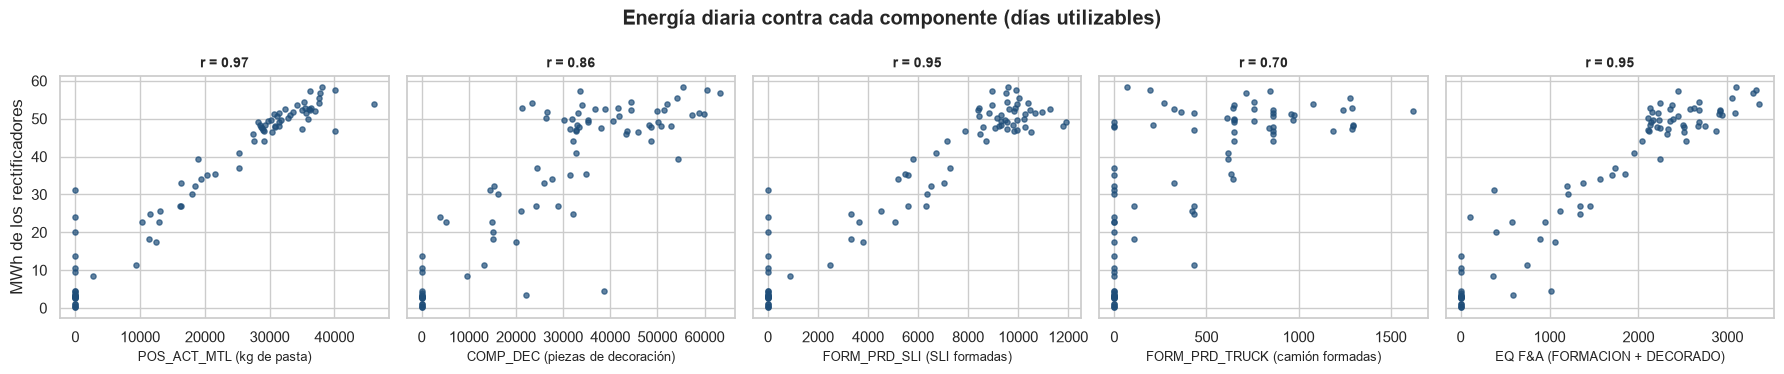

In [23]:
DRIVER_LABELS = {
    "q_POS_ACT_MTL": "POS_ACT_MTL (kg de pasta)",
    "q_COMP_DEC": "COMP_DEC (piezas de decoración)",
    "q_FORM_PRD_SLI": "FORM_PRD_SLI (SLI formadas)",
    "q_FORM_PRD_TRUCK": "FORM_PRD_TRUCK (camión formadas)",
    "eq": "EQ F&A (FORMACION + DECORADO)",
}
fig, axes = plt.subplots(1, len(DRIVER_LABELS), figsize=(18, 3.8), sharey=True)
measured_days = usable.dropna(subset=["kwh"])
for ax, (column, label) in zip(axes, DRIVER_LABELS.items(), strict=True):
    ax.scatter(measured_days[column], measured_days["kwh"] / 1000, s=14, color="#1f4e79", alpha=0.7)
    ax.set_xlabel(label, fontsize=9)
    ax.set_title(f"r = {measured_days[column].corr(measured_days['kwh']):.2f}", fontsize=10)
axes[0].set_ylabel("MWh de los rectificadores")
fig.suptitle("Energía diaria contra cada componente (días utilizables)", fontweight="bold")
plt.tight_layout()
plt.show()

In [24]:
def whole_weeks(frame: pd.DataFrame) -> pd.DataFrame:
    """Monday-to-Sunday weeks with all 7 days and no frozen day, summed."""
    week = frame.index.to_period("W-SUN")
    days = frame.groupby(week).size()
    frozen_weeks = set(week[frame["frozen"]])
    keep = [w for w, n in days.items() if n == 7 and w not in frozen_weeks]  # noqa: PLR2004
    summed = frame[week.isin(keep)].groupby(week[week.isin(keep)]).sum(numeric_only=True)
    summed.index = summed.index.map(lambda w: f"{w.start_time:%Y-%m-%d}")
    summed.index.name = "week from"
    return summed


weekly_drivers = whole_weeks(drivers_daily)
correlations = pd.DataFrame(
    {
        "daily pearson": measured_days[list(DRIVER_LABELS)].corrwith(measured_days["kwh"]),
        "daily spearman": measured_days[list(DRIVER_LABELS)].corrwith(
            measured_days["kwh"], method="spearman"
        ),
        "weekly pearson": weekly_drivers[list(DRIVER_LABELS)].corrwith(weekly_drivers["kwh"]),
        "weekly spearman": weekly_drivers[list(DRIVER_LABELS)].corrwith(
            weekly_drivers["kwh"], method="spearman"
        ),
    }
).rename(index=DRIVER_LABELS)
display(correlations)
print(f"Daily points: {len(measured_days)}; whole weeks without frozen days: {len(weekly_drivers)}")

,daily pearson,daily spearman,weekly pearson,weekly spearman
POS_ACT_MTL (kg de pasta),0.97,0.95,0.98,0.99
COMP_DEC (piezas de decoración),0.86,0.81,0.85,0.68
FORM_PRD_SLI (SLI formadas),0.95,0.87,0.99,0.93
FORM_PRD_TRUCK (camión formadas),0.70,0.72,0.68,0.53
EQ F&A (FORMACION + DECORADO),0.95,0.91,0.96,0.84


Daily points: 86; whole weeks without frozen days: 10


**Cómo leerlo.** La energía sigue sobre todo a la **pasta formada** (`POS_ACT_MTL`) y a las
**baterías SLI formadas**: correlación de 0,95 a 0,97 por día, y aún más alta por semana. Es lo
esperable: los rectificadores cargan las baterías que se están formando. Las **piezas de
decoración** acompañan menos (0,86), porque el decorado se contabiliza aparte de la formación y
no siempre el mismo día. Las baterías de **camión** (0,70) son pocas (alrededor de un 7 % de las
formadas) y su volumen pesa menos en el total. Todos los componentes suben juntos con la
producción, así que esta tabla no separa el efecto de cada uno: eso es trabajo de un modelo.

### b) Efecto mezcla: ¿cambió la razón cuando cambió la mezcla?

Por semana se mide la mezcla de cuatro maneras y se pone junto a la razón kWh/EQ de la misma
semana (Σ kWh / Σ EQ):

- **% camión**: baterías de camión sobre baterías formadas.
- **kg de pasta por batería formada**: más pasta por batería es una mezcla de baterías más grandes.
- **piezas de decoración por batería formada**.
- **% de EQ de DECORADO** dentro de las EQ de F&A.

In [25]:
weekly_mix = pd.DataFrame(
    {
        "kWh": weekly_drivers["kwh"],
        "EQ": weekly_drivers["eq"],
        "kWh per EQ": weekly_drivers["kwh"] / weekly_drivers["eq"],
        "truck share": weekly_drivers["q_FORM_PRD_TRUCK"] / weekly_drivers["formed"],
        "kg paste per formed": weekly_drivers["q_POS_ACT_MTL"] / weekly_drivers["formed"],
        "deco pieces per formed": weekly_drivers["q_COMP_DEC"] / weekly_drivers["formed"],
        "DECORADO share of EQ": weekly_drivers["eq_COMP_DEC"] / weekly_drivers["eq"],
    }
)
display(weekly_mix)
MIX = ["truck share", "kg paste per formed", "deco pieces per formed", "DECORADO share of EQ", "EQ"]
display(
    weekly_mix[MIX].corrwith(weekly_mix["kWh per EQ"], method="spearman")
    .rename("spearman with weekly kWh per EQ").to_frame()
)  # fmt: skip

,kWh,EQ,kWh per EQ,truck share,kg paste per formed,deco pieces per formed,DECORADO share of EQ
week from,,,,,,,
2026-07-06,"284,656.21","12,820.22",22.20,0.07,3.16,3.46,0.40
2026-07-27,"267,879.91","14,014.83",19.11,0.06,3.12,5.39,0.51
2026-08-03,"134,708.44","6,445.24",20.90,0.08,3.50,4.16,0.42
2026-08-10,"69,708.07","2,286.21",30.49,0.06,3.22,6.14,0.54
2026-08-17,"292,503.39","12,902.39",22.67,0.07,3.26,2.94,0.36
2026-08-24,"308,775.84","17,427.00",17.72,0.05,3.67,6.19,0.51
2026-08-31,"200,605.19","9,462.84",21.20,0.11,3.26,5.06,0.49
2026-09-07,"225,200.91","9,151.61",24.61,0.01,2.97,3.66,0.43
2026-09-14,"289,926.39","14,713.06",19.71,0.07,3.42,4.15,0.43


,spearman with weekly kWh per EQ
truck share,-0.12
kg paste per formed,-0.30
deco pieces per formed,-0.44
DECORADO share of EQ,-0.26
EQ,-0.79


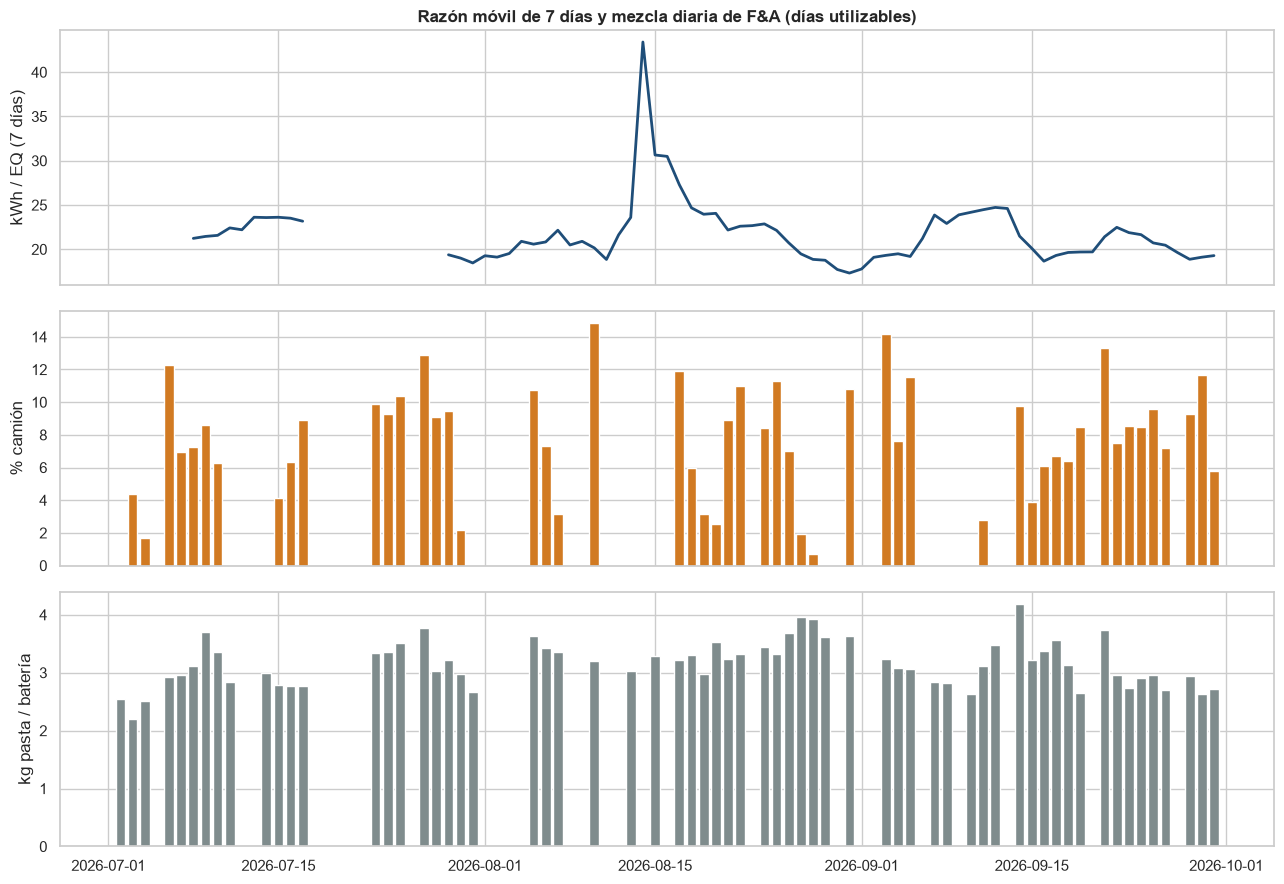

In [26]:
daily_mix = usable[usable["formed"] > 0]
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(daily["rolling_kwh_per_eq"], color="#1f4e79", lw=2)
axes[0].set_ylabel("kWh / EQ (7 días)")
axes[0].set_title("Razón móvil de 7 días y mezcla diaria de F&A (días utilizables)")
axes[1].bar(daily_mix.index, daily_mix["q_FORM_PRD_TRUCK"] / daily_mix["formed"] * 100,
            color="#d17a22")  # fmt: skip
axes[1].set_ylabel("% camión")
axes[2].bar(daily_mix.index, daily_mix["q_POS_ACT_MTL"] / daily_mix["formed"], color="#7f8c8d")
axes[2].set_ylabel("kg pasta / batería")
plt.tight_layout()
plt.show()

**Cómo leerlo.**

- **La mezcla casi no se mueve, y lo poco que se mueve no acompaña a la razón.** El % de camión
  va de menos de 1 % a 11 % según la semana, y su correlación de rangos con kWh/EQ es casi nula.
  Los kg de pasta por batería (unos 3,0 a 3,7) y las piezas de decoración por batería muestran
  a lo sumo una relación débil (−0,30 y −0,44), y en sentido contrario al que se esperaría si una
  mezcla más pesada costara más energía.
- **Lo que sí mueve la razón es el volumen.** Las semanas con pocas EQ tienen la razón más alta:
  la semana del 10 de agosto, con muy poca producción, pasa de 30 kWh/EQ. Es la carga base de los
  rectificadores repartida entre pocas baterías, lo mismo que mostró la recta de la sección 4.
- **Las piezas de decoración por batería saltan mucho de un día a otro y de una semana a otra.**
  Es un síntoma de la fecha contable: el decorado y la formación no se contabilizan juntos.
- **Con unas 10 semanas, todo esto es indicio y no conclusión.**

## 10. OREC y Ensamble: razón mensual y mezcla

Solo hay energía mensual (`Base_de_datos.xlsx`), así que la mezcla se mira por mes: la parte de
las EQ que aporta cada driver, y la proporción de camión en unidades. La razón solo existe en
los meses con energía (OREC hasta junio y Ensamble hasta julio de 2026).

In [27]:
def monthly_mix(area: AreaCross) -> pd.DataFrame:
    """One row per month: kWh per EQ, EQ, and each driver's share of the EQ and quantity."""
    records = []
    for row in area.rows:
        record = {
            "month": f"{row.start:%Y-%m}",
            "kWh per EQ": float("nan") if row.kwh_per_eq is None else float(row.kwh_per_eq),
            "EQ": float(row.eq),
        }
        for item in row.drivers:
            record[f"{item.cuenta_stats} share of EQ"] = (
                float(item.equs / row.eq) if row.eq else 0.0
            )
            record[f"q_{item.cuenta_stats}"] = float(item.cantidad)
        records.append(record)
    return pd.DataFrame(records).set_index("month")


mix_by_area = {
    area.area: monthly_mix(area) for area in fy_series.areas if area.area in ("OREC", "Ensamble")
}
orec_mix, ensamble_mix = mix_by_area["OREC"], mix_by_area["Ensamble"]
orec_mix["truck share of plates"] = orec_mix["q_PLATEPRD_TRUCK"] / (
    orec_mix["q_PLATEPRD_SLI"] + orec_mix["q_PLATEPRD_TRUCK"]
)
ensamble_mix["truck share of units"] = ensamble_mix["q_COSPRODU_TRUCK"] / (
    ensamble_mix["q_COSPRODU_SLI"] + ensamble_mix["q_COSPRODU_TRUCK"]
)
for name, frame in mix_by_area.items():
    shown = [c for c in frame.columns if not c.startswith("q_")]
    print(name)
    display(frame[shown])
    with_energy = frame.dropna(subset=["kWh per EQ"])
    mix_columns = [c for c in shown if c != "kWh per EQ"]
    display(
        with_energy[mix_columns].corrwith(with_energy["kWh per EQ"], method="spearman")
        .rename(f"spearman with kWh per EQ ({len(with_energy)} months)").to_frame()
    )  # fmt: skip
truck_vs_volume = ensamble_mix["truck share of units"].corr(ensamble_mix["EQ"], method="spearman")
print(f"Ensamble, truck share of units vs EQ (spearman, all 12 months): {truck_vs_volume:.2f}")

OREC


,kWh per EQ,EQ,GRIDS_CAST share of EQ,GRIDS_NEG share of EQ,GRIDS_REG_POS share of EQ,OXPROD_KG share of EQ,PLATEPRD_SLI share of EQ,PLATEPRD_TRUCK share of EQ,truck share of plates
month,,,,,,,,,
2025-10,6.11,"96,087.03",0.17,0.09,0.04,0.20,0.47,0.04,0.07
2025-11,7.61,"68,626.84",0.18,0.12,0.02,0.19,0.41,0.07,0.13
2025-12,7.03,"47,843.26",0.23,0.11,0.00,0.21,0.42,0.03,0.06
2026-01,6.75,"73,321.33",0.20,0.08,0.02,0.20,0.45,0.05,0.09
2026-02,6.20,"71,903.12",0.22,0.11,0.00,0.20,0.40,0.08,0.15
2026-03,7.38,"31,579.99",0.22,0.09,0.00,0.20,0.44,0.05,0.09
2026-04,6.02,"52,322.01",0.22,0.10,0.00,0.20,0.40,0.08,0.14
2026-05,6.90,"64,957.93",0.22,0.09,0.00,0.21,0.45,0.03,0.05
2026-06,6.71,"75,433.48",0.22,0.11,0.00,0.20,0.42,0.06,0.12


,spearman with kWh per EQ (9 months)
EQ,-0.47
GRIDS_CAST share of EQ,0.05
GRIDS_NEG share of EQ,0.25
GRIDS_REG_POS share of EQ,-0.05
OXPROD_KG share of EQ,0.02
PLATEPRD_SLI share of EQ,0.12
PLATEPRD_TRUCK share of EQ,-0.33
truck share of plates,-0.33


Ensamble


,kWh per EQ,EQ,COSPRODU_SLI share of EQ,COSPRODU_TRUCK share of EQ,truck share of units
month,,,,,
2025-10,2.35,"113,560.03",0.93,0.07,0.03
2025-11,3.36,"74,008.00",0.83,0.17,0.08
2025-12,2.87,"61,534.55",0.88,0.12,0.06
2026-01,2.94,"80,682.71",0.90,0.10,0.05
2026-02,2.81,"78,049.65",0.88,0.12,0.06
2026-03,5.37,"36,719.71",0.84,0.16,0.08
2026-04,3.81,"55,410.03",0.82,0.18,0.09
2026-05,3.10,"74,283.01",0.95,0.05,0.03
2026-06,2.42,"81,922.26",0.89,0.11,0.05


,spearman with kWh per EQ (10 months)
EQ,-0.72
COSPRODU_SLI share of EQ,-0.68
COSPRODU_TRUCK share of EQ,0.68
truck share of units,0.68


Ensamble, truck share of units vs EQ (spearman, all 12 months): -0.59


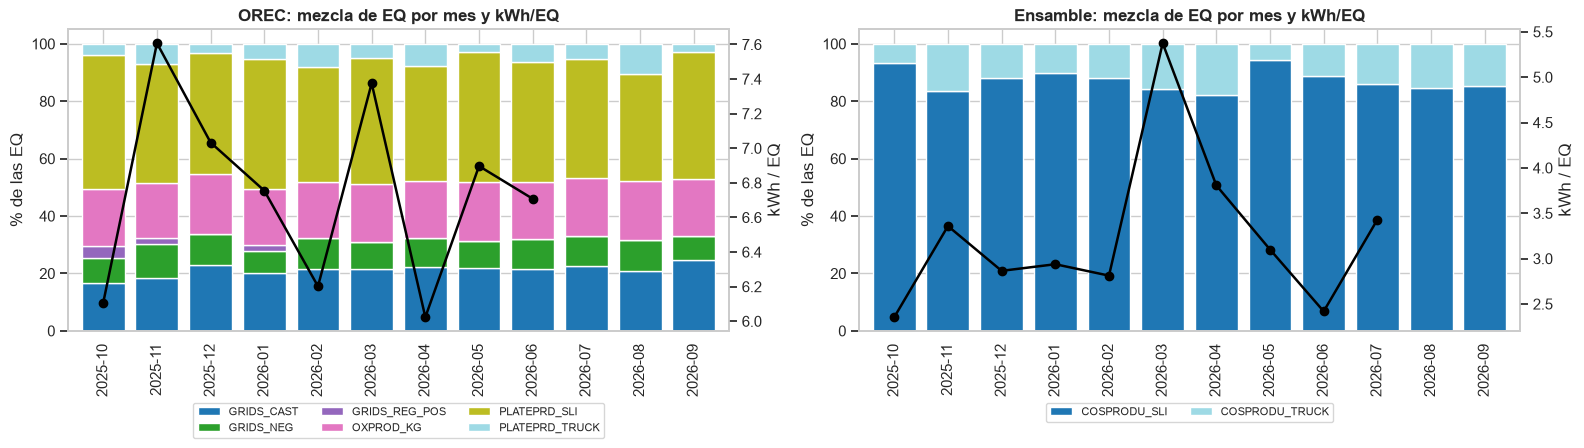

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (name, frame) in zip(axes, mix_by_area.items(), strict=True):
    shares = frame[[c for c in frame.columns if c.endswith("share of EQ")]] * 100
    shares.columns = [c.replace(" share of EQ", "") for c in shares.columns]
    shares.plot.bar(stacked=True, ax=ax, width=0.8, colormap="tab20", legend=False)
    ax.set_ylabel("% de las EQ")
    ax.set_xlabel("")
    ax.set_title(f"{name}: mezcla de EQ por mes y kWh/EQ")
    twin = ax.twinx()
    twin.plot(range(len(frame)), frame["kWh per EQ"], color="black", marker="o", lw=1.8)
    twin.set_ylabel("kWh / EQ")
    twin.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

**Cómo leerlo.**

- **OREC tiene una mezcla muy estable**: la parte de cada componente (óxido, rejillas, placas)
  cambia pocos puntos de un mes a otro, y ninguna se mueve junto con la razón de forma clara. La
  razón se relaciona más con el volumen del mes (meses de menos EQ, razón más alta) que con la
  mezcla.
- **En Ensamble, la parte de camión y el volumen se mueven en sentido contrario.** Marzo y abril,
  los dos meses de menor producción, están entre los de más camión y son los de razón más alta.
  En todo el año, la parte de camión baja cuando sube el volumen (correlación de rangos −0,59). Por
  eso la correlación de 0,68 entre camión y razón no dice si la razón sube por el camión o por la
  carga base repartida entre menos EQ. Para separarlos hacen falta más meses o datos diarios de
  Ensamble.
- Igual que en F&A, esto es descriptivo y con pocos puntos.

## 11. Resultados principales

Las cifras se recalculan arriba; esta celda solo las junta.

In [29]:
print(f"F&A, {CROSS_RANGE.start} to {CROSS_RANGE.end} ({fiscal}):")
print(f"  kWh per EQ, FORMACION + DECORADO (Σ/Σ): {float(fa_daily.total.kwh_per_eq):.2f}")
print("  by month:", ", ".join(f"{month} {ratio:.2f}"
                               for month, ratio in monthly["kwh_per_eq"].items()))  # fmt: skip
frozen_meters = ", ".join(run.meter for run in counters.frozen)
print(f"  days with kWh: {fa_daily.total.measured_days} of {fa_daily.total.days} "
      f"(frozen counters: {len(counters.frozen)}, {frozen_meters})")  # fmt: skip
print(f"  same-day correlation: {lags.loc[0, 'pearson']:.2f}; best lag k = {best_lag:+d}")
print(f"  7-day ratio: {summary['7-day min']:.2f} to {summary['7-day max']:.2f}, "
      f"median {summary['7-day median']:.2f}")  # fmt: skip
print("FY26, monthly, Σ kWh / Σ EQ of the months with energy:")
for area, item in fy_totals.iterrows():
    print(f"  {area}: {item['kWh per EQ']:.2f} ({item['months with energy']} months, "
          f"{item['energy source']})")  # fmt: skip
print(f"  F&A oct-2025 to jul-2026, Base_de_datos only: {float(book_only.total.kwh_per_eq):.2f}")
print(f"July 2026, F&A per day, SCADA vs Base_de_datos: "
      f"{july['SCADA vs Base_de_datos per day']:+.1%}")  # fmt: skip
print("EMCALI: neither RC alone nor the whole site; OREC and Ensamble stay monthly")
print("F&A components, daily (usable days), correlation of kWh with:",
      ", ".join(f"{label.split()[0]} {value:.2f}"
                for label, value in correlations["daily pearson"].items()))  # fmt: skip
weekly_ranks = weekly_mix[MIX].corrwith(weekly_mix["kWh per EQ"], method="spearman")
print(f"F&A weekly kWh per EQ, spearman with truck share {weekly_ranks['truck share']:+.2f}, "
      f"with EQ {weekly_ranks['EQ']:+.2f}")  # fmt: skip

F&A, 2026-07-02 to 2026-09-30 (FY26):
  kWh per EQ, FORMACION + DECORADO (Σ/Σ): 20.90
  by month: 2026-07 20.94, 2026-08 20.72, 2026-09 21.01
  days with kWh: 86 of 91 (frozen counters: 1, RECTIFICADOR 2)
  same-day correlation: 0.95; best lag k = +0
  7-day ratio: 17.32 to 43.40, median 21.22
FY26, monthly, Σ kWh / Σ EQ of the months with energy:
  F&A: 20.84 (12 months, Base_de_datos.xlsx + SCADA-Base de datos F&A.xlsx)
  OREC: 6.68 (9 months, Base_de_datos.xlsx)
  Ensamble: 3.07 (10 months, Base_de_datos.xlsx)
  F&A oct-2025 to jul-2026, Base_de_datos only: 20.83
July 2026, F&A per day, SCADA vs Base_de_datos: -2.1%
EMCALI: neither RC alone nor the whole site; OREC and Ensamble stay monthly
F&A components, daily (usable days), correlation of kWh with: POS_ACT_MTL 0.97, COMP_DEC 0.86, FORM_PRD_SLI 0.95, FORM_PRD_TRUCK 0.70, EQ 0.95
F&A weekly kWh per EQ, spearman with truck share -0.12, with EQ -0.79


**Para la siguiente etapa.**

- La herramienta reproduce la cifra del notebook anterior (**20,90 kWh por EQ**) sin copiar su
  lógica, y la deja fijada en `tests/integration/test_energy_cross_build.py`.
- El mismo cruce sale por línea de comandos: `make cruce START=2026-07-02 END=2026-09-30`
  (agregar `FREQUENCY=month` o `FORMAT=json|csv`).
- `Base_de_datos.xlsx` entra como fuente mensual de OREC, Ensamble y F&A, después del SCADA.
  Cada fila dice de qué fuente vienen sus kWh.
- F&A tiene **dos cifras** que no hay que confundir: **20,83** (oct-2025 a jul-2026, solo el
  libro) y **20,84** (FY26 completo, con SCADA en agosto y septiembre). OREC **6,68** y
  Ensamble **3,07** en FY26, con los meses que tienen energía.
- EMCALI no da energía diaria para OREC y Ensamble. Para tenerla haría falta un medidor por área,
  o saber exactamente qué alimenta EMCALI.
- Por componente, la energía diaria de F&A sigue a la pasta formada y a las baterías SLI
  formadas; la mezcla (camión, pasta por batería) no mueve la razón de forma visible, el volumen
  sí. En Ensamble, la parte de camión y el volumen van juntos y no se pueden separar con 10 meses.
  El desglose por driver queda en la herramienta (`row.drivers`, `row.frozen`) para el modelado.